In [1]:
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

from tensorflow.keras.models import Sequential
#this lets me build neural network layer by layer in keras
from tensorflow.keras.layers import Dense #dense makes the final prediction
from tensorflow.keras.layers import Conv2D #conv2d extract features
from tensorflow.keras.layers import Flatten #flatter reshape kore

from tensorflow.keras.layers import MaxPool2D #maxpooling kore- size reduce
from tensorflow.keras.layers import Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

from tensorflow.keras.utils import to_categorical #converts numerical into labels into one hot encoding format

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("abenjelloun/breast-mri-tumor-classification-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'breast-mri-tumor-classification-dataset' dataset.
Path to dataset files: /kaggle/input/breast-mri-tumor-classification-dataset


In [3]:
import os

dataset_path = "/kaggle/input/breast-mri-tumor-classification-dataset"

# check inside folders
for dir_name,subdir,filenames in os.walk(dataset_path):
    for filename in filenames:
        print(os.path.join(dir_name,filename))


Streaming output truncated to the last 5000 lines.
/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset/train/Malignant/BREASTDX-01-0010_15666.jpg
/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset/train/Malignant/BREASTDX-01-0003_1188.jpg
/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset/train/Malignant/BREASTDX-01-0046_4779.jpg
/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset/train/Malignant/BREASTDX-01-0018_12261.jpg
/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset/train/Malignant/BREASTDX-01-0069_7983.jpg
/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset/train/Malignant/BREASTDX-01-0065_10605.jpg
/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset/train/Malignant/BREASTDX-01-0022_8140.jpg
/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset/train/Malignant/BREASTDX-01-0068_12835.jpg
/kaggle/input/breast-mri-

In [4]:
import os
import matplotlib.pyplot as plt
from PIL import Image

# Base path (after kagglehub download)
BASE_PATH = "/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset_original_shape"

splits = ['train', 'val', 'test']
classes = ['Benign', 'Malignant']

# Count images per split per class
print(f"{'Split':<10} {'Benign':<12} {'Malignant':<12} {'Total'}")
print("-" * 44)
for split in splits:
    counts = {}
    for cls in classes:
        folder = os.path.join(BASE_PATH, split, cls)
        counts[cls] = len(os.listdir(folder))
    total = sum(counts.values())
    print(f"{split:<10} {counts['Benign']:<12} {counts['Malignant']:<12} {total}")

Split      Benign       Malignant    Total
--------------------------------------------
train      8413         8413         16826
val        1797         1797         3594
test       1802         1802         3604


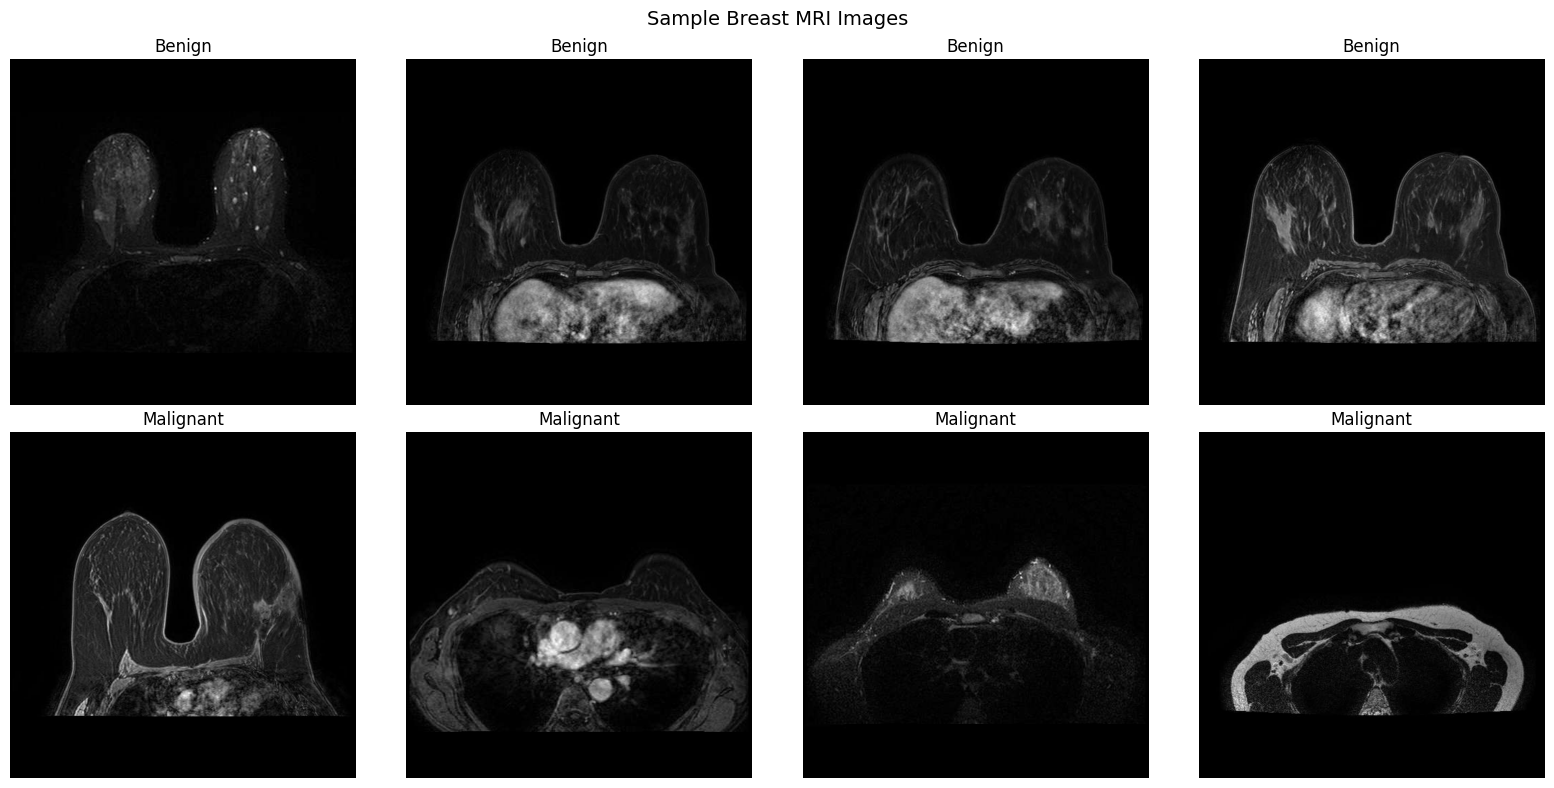

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle("Sample Breast MRI Images", fontsize=14)

for row, cls in enumerate(classes):
    folder = os.path.join(BASE_PATH, 'train', cls)
    sample_imgs = os.listdir(folder)[:4]
    for col, fname in enumerate(sample_imgs):
        img = Image.open(os.path.join(folder, fname)).convert('RGB')
        axes[row][col].imshow(img, cmap='gray')
        axes[row][col].set_title(f"{cls}")
        axes[row][col].axis('off')

plt.tight_layout()
plt.show()

In [15]:
import tensorflow as tf
import os

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Create optimized datasets (images remain unscaled in 0-255 range here; model will handle scaling)
train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(BASE_PATH, 'train'),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary',
    color_mode='rgb',
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(BASE_PATH, 'val'),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary',
    color_mode='rgb',
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(BASE_PATH, 'test'),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary',
    color_mode='rgb',
    shuffle=False
)

# Configure performance optimization with prefetching
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print("Optimized tf.data Datasets ready!")

Found 16826 files belonging to 2 classes.
Found 3594 files belonging to 2 classes.
Found 3604 files belonging to 2 classes.
Optimized tf.data Datasets ready!


In [16]:
# Define the data augmentation sequential block
data_augmentation = Sequential([
    tf.keras.layers.Rescaling(1./255), # Rescale pixel values [0, 255] to [0.0, 1.0]
    tf.keras.layers.RandomRotation(0.027),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomTranslation(height_factor=0.05, width_factor=0.05),
    tf.keras.layers.RandomFlip("horizontal")
])

# Building the CNN with Integrated Augmentation Layers
CNN = Sequential([
    # Input layer specification
    tf.keras.layers.Input(shape=(224, 224, 3)),

    # Augmentation & Rescaling layers (Only active during training, auto-bypassed during validation/testing)
    data_augmentation,

    # Feature Extraction Convolutional Blocks
    Conv2D(32, (3, 3), activation='relu'),
    MaxPool2D(2, 2),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPool2D(2, 2),

    Conv2D(128, (3, 3), activation='relu'),
    MaxPool2D(2, 2),

    # Fully Connected Dense Classifier
    Flatten(),
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

CNN.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_3 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │    44,302,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,396,609 (169.36 MB)

 Trainable params: 44,396,609 (169.36 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
CNN.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy',tf.keras.metrics.AUC(name='auc')] #auc for medical
)

In [ ]:
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ModelCheckpoint('best_breast_mri_model.keras', monitor='val_auc', save_best_only=True, mode='max'),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1)
]

# Start high-speed training on pre-fetched TF datasets with native GPU augmentations!
history = CNN.fit(
    train_ds,
    epochs=30,
    validation_data=val_ds,
    callbacks=callbacks
)

Epoch 1/30
526/526 ━━━━━━━━━━━━━━━━━━━━ 80s 133ms/step - accuracy: 0.6284 - auc: 0.6810 - loss: 0.6410 - val_accuracy: 0.7298 - val_auc: 0.8173 - val_loss: 0.5124 - learning_rate: 0.0010
Epoch 2/30
526/526 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - accuracy: 0.7197 - auc: 0.7928 - loss: 0.5438 - val_accuracy: 0.7880 - val_auc: 0.8771 - val_loss: 0.4273 - learning_rate: 0.0010
Epoch 3/30
526/526 ━━━━━━━━━━━━━━━━━━━━ 55s 105ms/step - accuracy: 0.7645 - auc: 0.8493 - loss: 0.4735 - val_accuracy: 0.8408 - val_auc: 0.9280 - val_loss: 0.3427 - learning_rate: 0.0010
Epoch 4/30
526/526 ━━━━━━━━━━━━━━━━━━━━ 54s 103ms/step - accuracy: 0.8001 - auc: 0.8888 - loss: 0.4139 - val_accuracy: 0.8756 - val_auc: 0.9529 - val_loss: 0.2820 - learning_rate: 0.0010
Epoch 5/30
526/526 ━━━━━━━━━━━━━━━━━━━━ 85s 109ms/step - accuracy: 0.8213 - auc: 0.9109 - loss: 0.3737 - val_accuracy: 0.8804 - val_auc: 0.9615 - val_loss: 0.2515 - learning_rate: 0.0010
Epoch 6/30
526/526 ━━━━━━━━━━━━━━━━━━━━ 52s 100ms/step - accuracy

In [11]:
import tensorflow as tf
gpus = tf.config.list_physical_devices('GPU')
print("GPUS available:", gpus)
if len(gpus) == 0:
    print("\n[WARNING]: No GPU detected! Please change your runtime type in Colab:\n"
          "Go to Menu -> Runtime -> Change runtime type -> Select 'T4 GPU' (or another GPU option) under Hardware accelerator.")
else:
    print("\n[INFO]: GPU detected! TensorFlow is configured to use:", gpus)

GPUS available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

[INFO]: GPU detected! TensorFlow is configured to use: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
